# HandX LMDB — inspection and MANO visualization

In [1]:
from pathlib import Path
import pickle
import pprint
import sys

import lmdb
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'configs' / 'data' / 'handx.yaml').is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data import Mano3DPlot, get_handx_loaders

LMDB_PATH = PROJECT_ROOT / 'datasets' / 'preprocessed' / 'handx'
BATCH_SIZE = 4
FPS = 20

In [2]:
environment = lmdb.open(
    str(LMDB_PATH),
    subdir=True,
    readonly=True,
    lock=False,
    readahead=False,
)
with environment.begin() as transaction:
    metadata = pickle.loads(transaction.get(b'__metadata__'))
    statistics = pickle.loads(transaction.get(b'__statistics__'))
    train_keys = pickle.loads(transaction.get(b'__keys__/train'))
    test_keys = pickle.loads(transaction.get(b'__keys__/test'))
    first_record = pickle.loads(transaction.get(train_keys[0].encode('utf-8')))
    lmdb_header = {
        'info': environment.info(),
        'stat': environment.stat(),
        'metadata': metadata,
        'train_entries': len(train_keys),
        'test_entries': len(test_keys),
        'statistics': {
            key: {'shape': value.shape, 'dtype': str(value.dtype)}
            if isinstance(value, np.ndarray) else value
            for key, value in statistics.items()
        },
    }
environment.close()

def describe(value):
    if isinstance(value, np.ndarray):
        return {
            'type': 'ndarray',
            'shape': value.shape,
            'dtype': str(value.dtype),
            'min': float(value.min()),
            'max': float(value.max()),
        }
    if isinstance(value, list):
        return {
            'type': 'list',
            'length': len(value),
            'first': value[0] if value else None,
        }
    return value

print('LMDB HEADER')
pprint.pp(lmdb_header, sort_dicts=False)
print('\nFIRST RECORD')
pprint.pp(
    {key: describe(value) for key, value in first_record.items()},
    sort_dicts=False,
)

LMDB HEADER
{'info': {'map_addr': 0,
          'map_size': 9950507008,
          'last_pgno': 2429322,
          'last_txnid': 184,
          'max_readers': 126,
          'num_readers': 0},
 'stat': {'psize': 4096,
          'depth': 3,
          'branch_pages': 7,
          'leaf_pages': 824,
          'overflow_pages': 2428479,
          'entries': 94382},
 'metadata': {'version': 1,
              'serialization': 'pickle',
              'dataset': 'HandX',
              'feature_dimension': 198,
              'feature_dtype': 'float32',
              'feature_shape': ['T', 198],
              'joint_positions_shape': ['T', 2, 21, 3],
              'feature_layout': {'left': {'range': [0, 99],
                                          'translation': [0, 3],
                                          'rotation_6d': [3, 99],
                                          'rotation_shape': [16, 6]},
                                 'right': {'range': [99, 198],
                              

In [3]:
loaders = get_handx_loaders(
    batch_size=BATCH_SIZE,
    num_workers=0,
    use_paraphrases=True,
    normalize_motion=False,
    normalize_text=False,
)
batch = next(iter(loaders['train']))
sample = loaders['test'].dataset[0]

print({split: len(loader.dataset) for split, loader in loaders.items()})
print('\nTRAIN BATCH')
for key, value in batch.items():
    if torch.is_tensor(value):
        print(f'{key:22s} Tensor shape={tuple(value.shape)!s:20s} dtype={value.dtype}')
    elif isinstance(value, (list, tuple)):
        preview = value[0] if value else None
        print(f'{key:22s} {type(value).__name__} len={len(value)} first={preview!r}')
    else:
        print(f'{key:22s} {type(value).__name__}: {value!r}')

{'train': 84729, 'test': 9648}

TRAIN BATCH
id                     list len=4 first='train/00043692'
dataset                list len=4 first='handx'
split                  list len=4 first='train'
index                  Tensor shape=(4,)                 dtype=torch.int64
source_key             list len=4 first='43692'
source                 list len=4 first='HoloAssist'
x                      Tensor shape=(4, 60, 198)         dtype=torch.float32
length                 Tensor shape=(4,)                 dtype=torch.int64
frame_mask             Tensor shape=(4, 60)              dtype=torch.bool
is_left_hand           Tensor shape=(4,)                 dtype=torch.bool
is_right_hand          Tensor shape=(4,)                 dtype=torch.bool
left_shape             Tensor shape=(4, 60, 10)          dtype=torch.float32
right_shape            Tensor shape=(4, 60, 10)          dtype=torch.float32
joint_positions        Tensor shape=(4, 60, 2, 21, 3)    dtype=torch.float32
texts                 

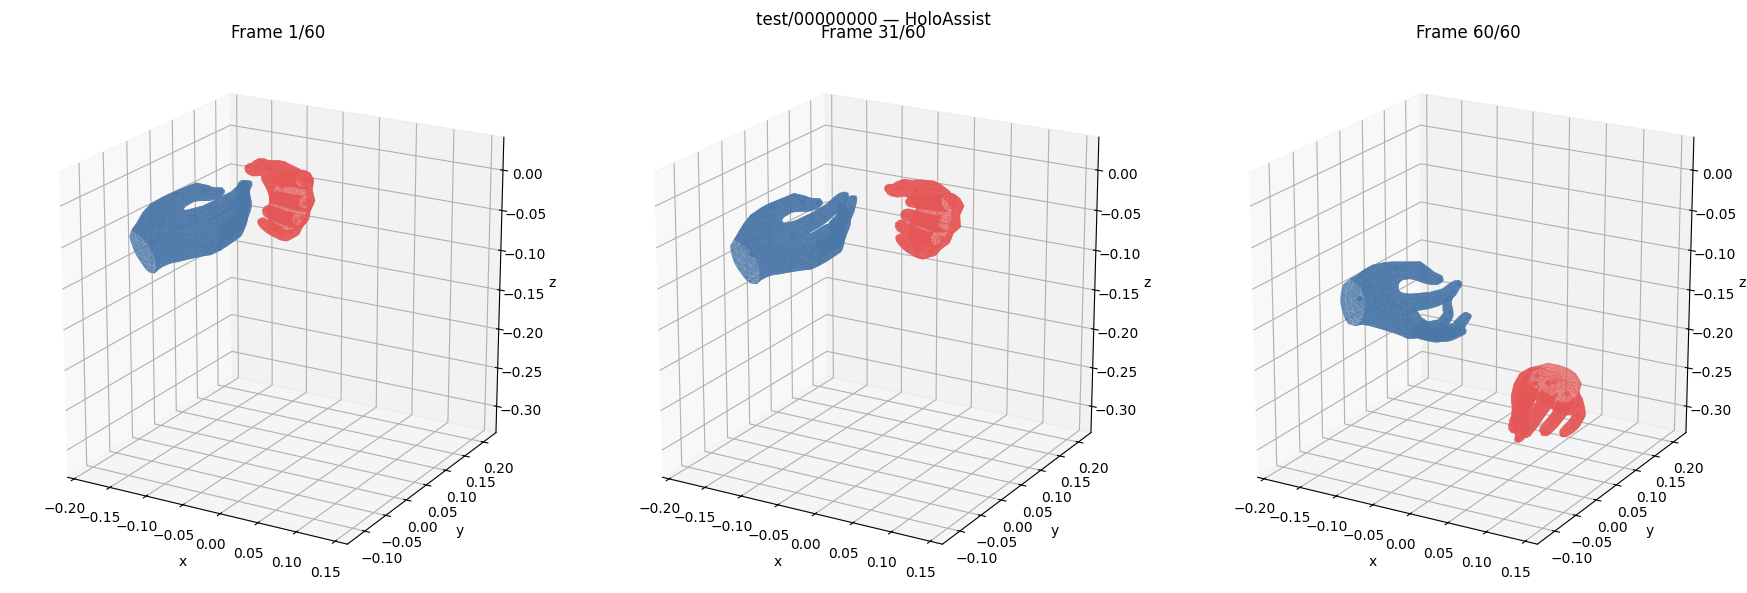

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
visualizer = Mano3DPlot(device=device, fps=FPS)
decoded = visualizer.decode_features(
    sample['x'],
    sample['left_shape'],
    sample['right_shape'],
)
left_vertices = decoded['left_vertices']
right_vertices = decoded['right_vertices']
left_faces = decoded['left_faces']
right_faces = decoded['right_faces']
frame_count = int(sample['length'])
frame_ids = [0, frame_count // 2, frame_count - 1]
all_vertices = np.concatenate((left_vertices, right_vertices), axis=1).reshape(-1, 3)
minimum = all_vertices.min(axis=0)
maximum = all_vertices.max(axis=0)
center = (minimum + maximum) / 2
radius = max((maximum - minimum).max() / 2, 1e-3)

figure, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
    subplot_kw={'projection': '3d'},
)
for axis, frame_id in zip(axes, frame_ids):
    axis.add_collection3d(Poly3DCollection(
        left_vertices[frame_id][left_faces],
        facecolor=visualizer.left_color,
        edgecolor='none',
        alpha=0.85,
    ))
    axis.add_collection3d(Poly3DCollection(
        right_vertices[frame_id][right_faces],
        facecolor=visualizer.right_color,
        edgecolor='none',
        alpha=0.85,
    ))
    joints = sample['joint_positions'][frame_id].numpy()
    axis.scatter(*joints[0].T, color=visualizer.left_color, s=8)
    axis.scatter(*joints[1].T, color=visualizer.right_color, s=8)
    axis.set_xlim(center[0] - radius, center[0] + radius)
    axis.set_ylim(center[1] - radius, center[1] + radius)
    axis.set_zlim(center[2] - radius, center[2] + radius)
    axis.set_box_aspect((1, 1, 1))
    axis.view_init(elev=20, azim=-60)
    axis.set_title(f'Frame {frame_id + 1}/{frame_count}')
    axis.set_xlabel('x')
    axis.set_ylabel('y')
    axis.set_zlabel('z')
figure.suptitle(f"{sample['id']} — {sample['source']}")
figure.tight_layout()
plt.show()

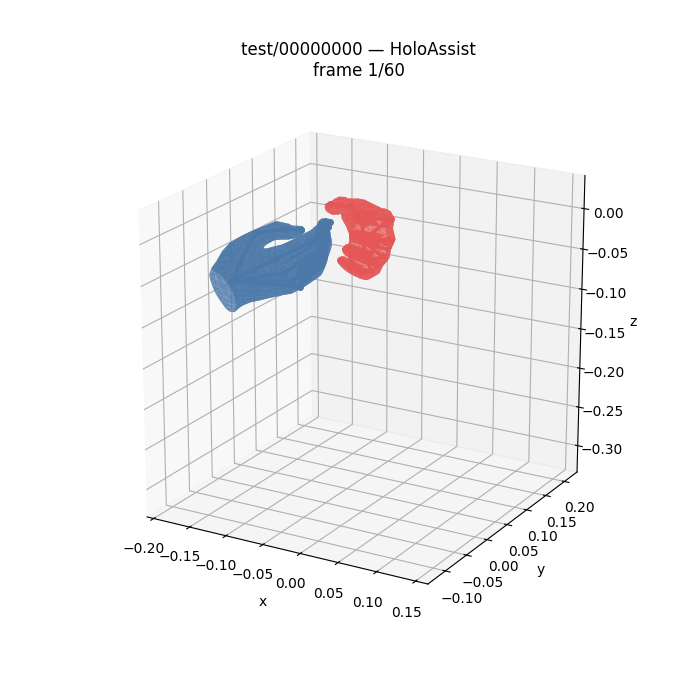

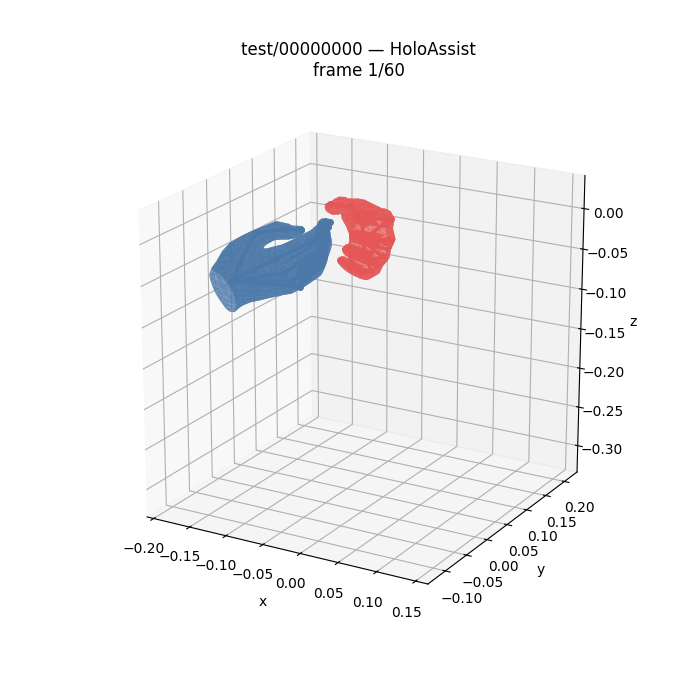

In [5]:
try:
    import ipympl
    get_ipython().run_line_magic('matplotlib', 'widget')
    widget_backend = True
except ImportError:
    widget_backend = False

animation = visualizer.animate_record(
    sample,
    show_joints=True,
    title=f"{sample['id']} — {sample['source']}",
    max_frames=None,
    repeat=True,
)
if widget_backend:
    display(animation._fig.canvas)
else:
    display(HTML(animation.to_jshtml(fps=FPS, default_mode='loop')))
    plt.close(animation._fig)